# 03 Univariate EDA

This notebook is a starting point for univariate exploratory data analysis on the cleaned ElectraHub dataset.

Suggested flow:
- load the cleaned dataset
- review column types
- inspect numeric distributions
- inspect categorical frequency tables
- note key findings for each variable

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

dataset_path = Path("../data/processed/ElectraHub_Data_cleaned.csv")
df = pd.read_csv(dataset_path)

print(f"Dataset path: {dataset_path}")
print(f"Rows loaded: {len(df)}")
print(f"Columns loaded: {len(df.columns)}")

Dataset path: ../data/processed/ElectraHub_Data_cleaned.csv
Rows loaded: 3000
Columns loaded: 16


In [3]:
df.head()

  Region Product_Category  ... Popularity     Sales
0  South           Tablet  ...   Moderate  12265.79
1   West           Tablet  ...       High  20426.45
2   West           Mobile  ...       High  29827.18
3   East           Tablet  ...   Moderate  28211.95
4  North           Mobile  ...       High  29794.80

[5 rows x 16 columns]

In [4]:
df.dtypes

Region                         object
Product_Category               object
Campaign_Type                  object
Product_Age_Months              int64
Product_Price                 float64
Competitor_Price_Index        float64
Advertising_Expenditure       float64
Discount_Percentage           float64
Campaign_Engagement_Score     float64
Inventory_Level                 int64
Num_Reviews                     int64
Avg_Customer_Rating           float64
Return_Rate                   float64
Length_Product_Description      int64
Popularity                     object
Sales                         float64
dtype: object

In [5]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

Numeric columns: ['Product_Age_Months', 'Product_Price', 'Competitor_Price_Index', 'Advertising_Expenditure', 'Discount_Percentage', 'Campaign_Engagement_Score', 'Inventory_Level', 'Num_Reviews', 'Avg_Customer_Rating', 'Return_Rate', 'Length_Product_Description', 'Sales']
Categorical columns: ['Region', 'Product_Category', 'Campaign_Type', 'Popularity']


## Numeric Variables

Use this section to review summary statistics, spread, skew, and possible outliers.

In [7]:
df[numeric_columns].describe().T

                             count          mean  ...         75%        max
Product_Age_Months          3000.0     11.316000  ...     15.0000     36.000
Product_Price               3000.0    980.839717  ...   1475.7200   2000.000
Competitor_Price_Index      3000.0      0.999106  ...      1.0550      1.250
Advertising_Expenditure     3000.0    623.781673  ...    683.4000    820.000
Discount_Percentage         3000.0     29.439540  ...     33.0700     42.000
Campaign_Engagement_Score   3000.0     52.344707  ...     62.5700     99.000
Inventory_Level             3000.0    821.361333  ...   1020.2500   1840.000
Num_Reviews                 3000.0    418.200000  ...    549.0000   2989.000
Avg_Customer_Rating         3000.0      3.984093  ...      4.0700      4.420
Return_Rate                 3000.0      2.770218  ...      3.0450      4.279
Length_Product_Description  3000.0    247.311000  ...    290.0000    448.000
Sales                       3000.0  26252.858620  ...  31208.4225  40000.000

### Sales Distribution

The chart below shows the Sales histogram with a smooth density curve and reference lines for the mean and median.

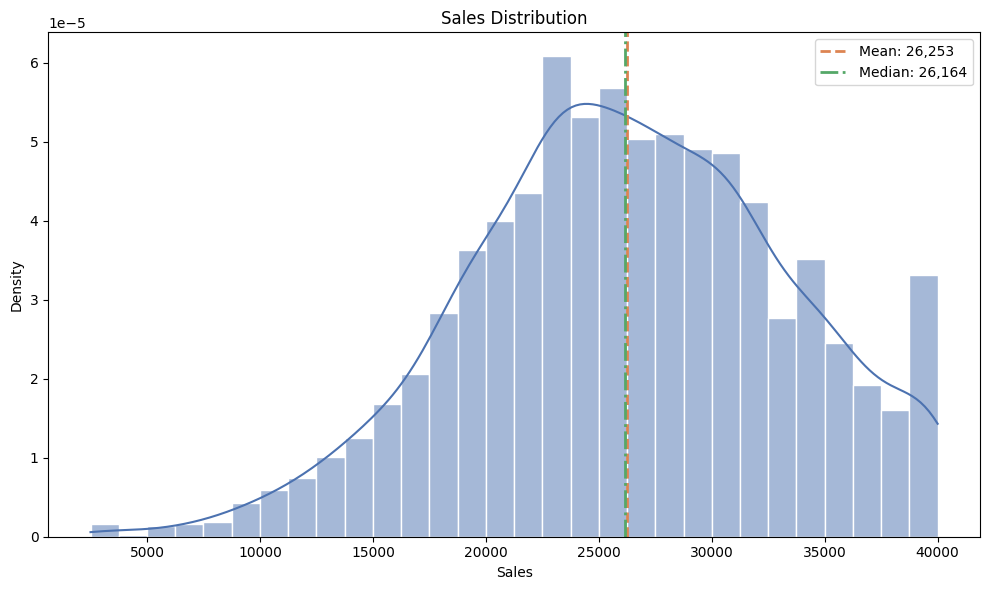

In [9]:
sales_mean = df["Sales"].mean()
sales_median = df["Sales"].median()

plt.figure(figsize=(10, 6))
ax = sns.histplot(df["Sales"], bins=30, kde=True, stat="density", color="#4C72B0", edgecolor="white")
ax.axvline(sales_mean, color="#DD8452", linestyle="--", linewidth=2, label=f"Mean: {sales_mean:,.0f}")
ax.axvline(sales_median, color="#55A868", linestyle="-.", linewidth=2, label=f"Median: {sales_median:,.0f}")
ax.set_title("Sales Distribution")
ax.set_xlabel("Sales")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

### Advertising Expenditure Distribution

The panels below show the spread of Advertising_Expenditure, highlight any outliers, and make it easier to judge symmetry.

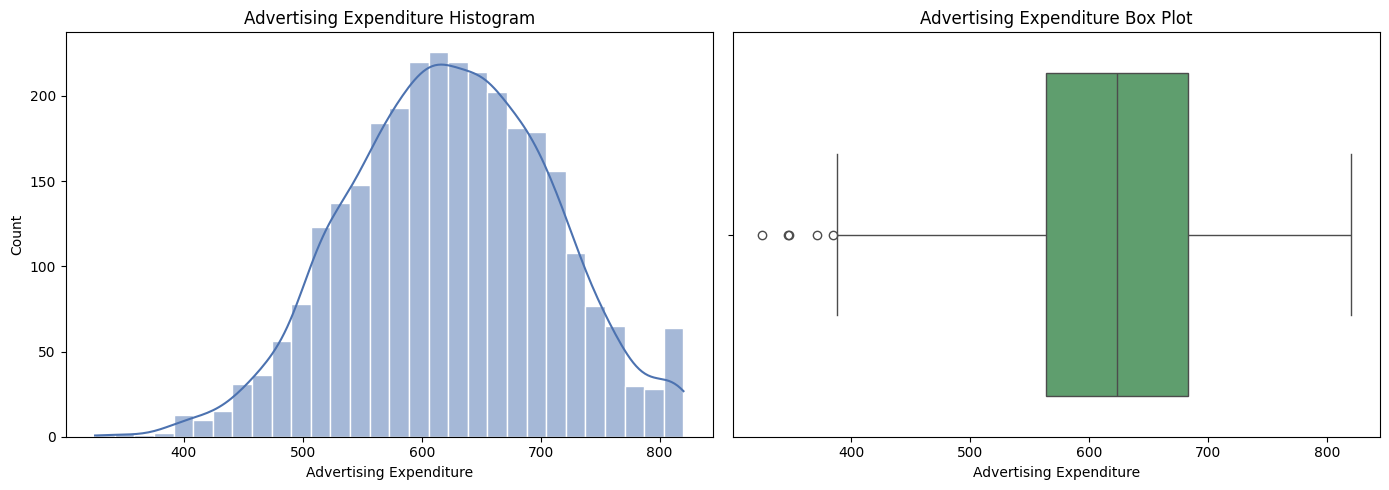

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Advertising_Expenditure"], bins=30, kde=True, color="#4C72B0", edgecolor="white", ax=axes[0])
axes[0].set_title("Advertising Expenditure Histogram")
axes[0].set_xlabel("Advertising Expenditure")
axes[0].set_ylabel("Count")

sns.boxplot(x=df["Advertising_Expenditure"], color="#55A868", ax=axes[1])
axes[1].set_title("Advertising Expenditure Box Plot")
axes[1].set_xlabel("Advertising Expenditure")

plt.tight_layout()
plt.show()

## Categorical Variables

Use this section to inspect category counts and spot imbalance or unusual labels.

In [13]:
for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


Region
Region
West     845
East     815
South    690
North    650
Name: count, dtype: int64

Product_Category
Product_Category
Mobile    1884
Tablet    1116
Name: count, dtype: int64

Campaign_Type
Campaign_Type
Social Media    937
Search Ad       866
Email           624
Influencer      573
Name: count, dtype: int64

Popularity
Popularity
High         990
Very High    840
Moderate     660
Low          420
Very Low      90
Name: count, dtype: int64


### Popularity Distribution

The chart below shows Popularity ordered from Very Low to Very High.

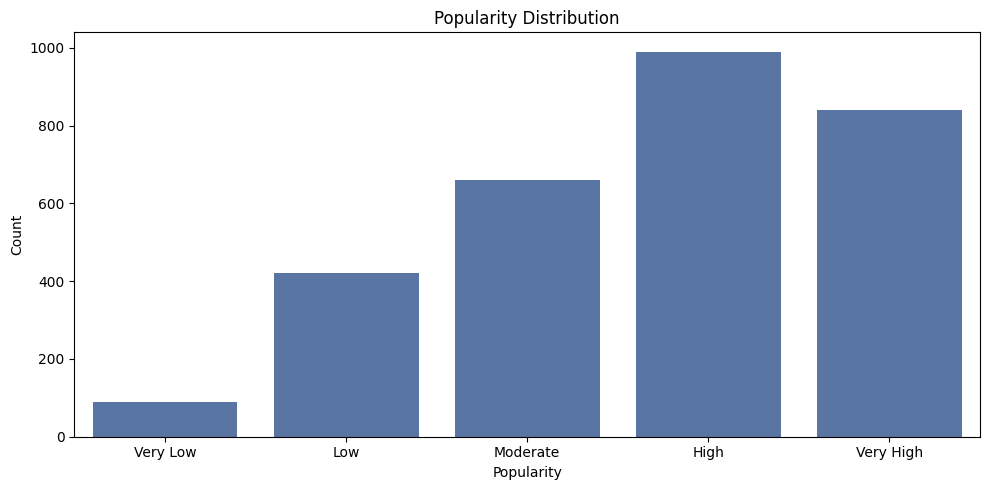

In [15]:
popularity_order = ["Very Low", "Low", "Moderate", "High", "Very High"]
popularity_counts = df["Popularity"].value_counts().reindex(popularity_order)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=popularity_counts.index, y=popularity_counts.values, color="#4C72B0")
ax.set_title("Popularity Distribution")
ax.set_xlabel("Popularity")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

## Findings

Document your main univariate insights here.